# 1. Definición del problema y ficha de datos

En este capítulo planteamos el problema de predecir clics en anuncios móviles, lo formalizamos y declaramos, antes de entrenar, las preguntas de investigación, las hipótesis, las métricas y el protocolo que rigen todo el trabajo. También justificamos el uso de Avazu y presentamos la ficha de datos.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

Resultados: results | prueba de humo: False


## 1.1 Contexto y motivación

En la publicidad móvil programática, la plataforma decide en milisegundos qué anuncio mostrar en cada impresión. El valor esperado de una impresión es el producto entre la probabilidad de clic (*click-through rate*, CTR) y lo que el anunciante paga por clic, por lo que el sistema necesita estimaciones de probabilidad, no solo un orden entre anuncios. Una probabilidad mal calibrada desplaza las pujas aunque el ordenamiento sea correcto (McMahan et al., 2013).

Los datos de CTR tienen cuatro rasgos que condicionan el modelado:

- **Variables categóricas de alta cardinalidad:** identificadores de sitio, aplicación, dispositivo e IP con miles o millones de valores distintos.
- **Desbalance:** la mayoría de las impresiones no recibe clic.
- **Deriva temporal:** la tasa de clics y la mezcla de sitios y aplicaciones cambian de un día a otro.
- **Volumen:** decenas de millones de registros por semana, lo que pone a prueba las herramientas de una sola máquina frente a las distribuidas.

Por estos rasgos, el problema sirve para comparar scikit-learn y PySpark en condiciones realistas y para examinar qué aporta un MLP frente a modelos más simples.

## 1.2 Definición formal del problema

El proyecto corresponde al tipo **1. Clasificación (datos tabulares)**, con un objetivo binario.

**Espacio de entrada.** Cada impresión se describe con 24 variables categóricas: las 21 originales de Avazu y tres derivadas del campo `hour` (hora del día, día de la semana y franja horaria). Si $\mathcal{V}_j$ es el conjunto de valores de la variable $j$,

$$\mathcal{X} = \mathcal{V}_1 \times \mathcal{V}_2 \times \cdots \times \mathcal{V}_{24}.$$

**Espacio de salida.** $\mathcal{Y} = \{0, 1\}$, donde $y = 1$ indica que la impresión recibió un clic.

**Codificación.** Una red neuronal necesita entradas numéricas, por lo que cada estrategia de codificación $e$ define una función $\phi_e : \mathcal{X} \to \mathbb{R}^{d_e}$. Con *hashing*, por ejemplo,

$$\phi_e(x)_k = \sum_{j=1}^{24} \mathbb{1}\big[\, h(\text{"}j\text{=}x_j\text{"}) \bmod d_e = k \,\big], \qquad k = 0, \dots, d_e - 1,$$

donde $h$ es una función hash y $d_e \in \{2^{12}, 2^{14}, 2^{16}\}$. El capítulo 3 define las demás estrategias.

**Función objetivo.** Buscamos $f_\theta : \mathcal{X} \to [0, 1]$ que estime $P(y = 1 \mid x)$. El MLP con $L$ capas ocultas calcula

$$a^{(0)} = \phi_e(x), \qquad a^{(l)} = g\big(W^{(l)} a^{(l-1)} + b^{(l)}\big),\; l = 1, \dots, L, \qquad f_\theta(x) = \sigma\big(w^\top a^{(L)} + b\big),$$

con $g$ la activación de las capas ocultas (ReLU en scikit-learn, sigmoide en el MLP de Spark) y $\sigma(z) = 1/(1 + e^{-z})$. El MLP de Spark termina en una capa *softmax* de dos neuronas; como $\operatorname{softmax}(z_0, z_1)_1 = \sigma(z_1 - z_0)$, ambas salidas son equivalentes.

**Función de pérdida.** Minimizamos la entropía cruzada binaria (*log loss*) con penalización $L_2$:

$$\mathcal{L}(\theta) = -\frac{1}{N} \sum_{i=1}^{N} w_{y_i} \Big[ y_i \log f_\theta(x_i) + (1 - y_i) \log\big(1 - f_\theta(x_i)\big) \Big] + \frac{\alpha}{2N} \sum_{l} \lVert W^{(l)} \rVert_F^2,$$

con $w_0 = w_1 = 1$ sin ponderación y $w_k = N / (2 N_k)$ cuando ponderamos por clase, donde $N_k$ es el número de impresiones de la clase $k$ en entrenamiento.

**Regla de decisión.** La clase predicha es $\hat y = \mathbb{1}[f_\theta(x) \ge \tau]$, con el umbral $\tau$ elegido en validación como el que maximiza el F1.

## 1.3 Preguntas de investigación e hipótesis

**P1. Punto de cruce.** ¿A partir de qué volumen de entrenamiento PySpark entrena más rápido que scikit-learn sin degradar la calidad predictiva?

Sea $T_{\text{env}}(n)$ el tiempo de entrenamiento con $n$ filas. Definimos el punto de cruce como $n^\* = \min\{n : T_{\text{Spark}}(n) < T_{\text{sklearn}}(n)\}$, siempre que la diferencia de ROC AUC entre entornos sea menor que $\delta$. Para que la comparación mida el motor y no el modelo, ambos entornos entrenan el mismo modelo: la misma entrada (*hashing* $2^{12}$), la misma arquitectura, la misma activación sigmoide y el mismo optimizador (L-BFGS) con el mismo número máximo de iteraciones.

- **H1:** existe un $n^\*$ medible, y para $n < n^\*$ scikit-learn es más eficiente.

**P2. Codificación de alta cardinalidad.** ¿Cómo afecta la codificación (*hashing*, frecuencia, *target encoding*) al desempeño y al costo computacional?

- **H2:** el *hashing* con dimensión moderada ($2^{14}$) alcanza un ROC AUC equivalente al de la codificación por frecuencia (diferencia dentro de $\pm\delta$) con una fracción de su memoria.

**P3. Aporte del MLP.** ¿Mejora el MLP de forma estadísticamente significativa a las líneas base (regresión logística y árboles potenciados)?

- $H_0$: $\mathbb{E}\big[\text{AUC}_{\text{MLP}}^{(s)} - \text{AUC}_{\text{base}}^{(s)}\big] \le 0$, con la diferencia pareada por semilla $s$.
- $H_1$: la diferencia es positiva. Una mejora es relevante si es significativa tras la corrección de Holm y su magnitud alcanza $\delta$.

**P4. Calidad de las explicaciones.** ¿Son las explicaciones de LIME estables y fieles al modelo?

- Consideramos **estable** una explicación si la similitud de Jaccard media entre las 5 variables principales, en 10 repeticiones con semillas distintas, es al menos 0.8.
- Consideramos **fiel** una explicación si el $R^2$ mediano del modelo sustituto local es al menos 0.5.

## 1.4 Decisiones declaradas antes del entrenamiento

Fijamos estas decisiones en `src/config.py` antes de la búsqueda de hiperparámetros y de las corridas definitivas. No cambian después de ver resultados de prueba.

In [2]:
decisiones = [
    ("Tipo de problema", "Clasificación binaria con datos tabulares (tipo 1)"),
    ("Métrica primaria", "ROC AUC en prueba (día 30)"),
    ("Métricas secundarias", "PR AUC, log loss, Brier, ECE; accuracy, precision, recall y F1 con umbral elegido en validación; lift y ganancia acumulada"),
    ("Margen de relevancia práctica", f"δ = {C.DELTA_AUC} en ROC AUC"),
    ("Significancia", f"α = {C.ALPHA}, corrección de Holm en las comparaciones múltiples"),
    ("Partición", f"Temporal: entrenamiento días {C.TRAIN_DAYS[0]}–{C.TRAIN_DAYS[-1]}, validación día {C.VAL_DAY}, prueba día {C.TEST_DAY}"),
    ("Unidad de observación", "La impresión (una fila)"),
    ("Unidad de réplica", f"La semilla ({len(C.SEEDS)} semillas: {', '.join(map(str, C.SEEDS))}); controla la inicialización, el orden de los lotes y la partición interna de la parada temprana"),
    ("Tamaños de entrenamiento", ", ".join(f"{k} ({R.num(v)} filas)" for k, v in C.SIZES.items()) + f"; tamaño principal {C.MAIN_SIZE}"),
    ("Validación", f"{R.num(C.VAL_ROWS)} filas del día {C.VAL_DAY}" ),
    ("Prueba", f"Todo el día {C.TEST_DAY}, congelado con huella SHA-256"),
    ("Categorías raras", f"Menos de {C.RARE_MIN_COUNT} apariciones en entrenamiento → `{C.RARE_TOKEN}`"),
    ("Codificaciones", ", ".join(C.ENCODING_LABELS.values())),
    ("Baja cardinalidad", f"≤ {C.LOW_CARD_MAX} categorías tras agrupar raras: one-hot en las estrategias densas"),
    ("Búsqueda de hiperparámetros", f"Optuna (TPE), {C.OPTUNA_TRIALS} intentos para el MLP y {C.OPTUNA_TRIALS_BASELINES} para cada línea base, maximizando ROC AUC en validación"),
    ("Presupuesto por ajuste", f"{C.FIT_BUDGET_MIN} min; un ajuste con duración estimada mayor se omite y se reporta con su estimación"),
]
display(Markdown("| Decisión | Valor |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in decisiones)))

| Decisión | Valor |
|---|---|
| Tipo de problema | Clasificación binaria con datos tabulares (tipo 1) |
| Métrica primaria | ROC AUC en prueba (día 30) |
| Métricas secundarias | PR AUC, log loss, Brier, ECE; accuracy, precision, recall y F1 con umbral elegido en validación; lift y ganancia acumulada |
| Margen de relevancia práctica | δ = 0.005 en ROC AUC |
| Significancia | α = 0.05, corrección de Holm en las comparaciones múltiples |
| Partición | Temporal: entrenamiento días 21–28, validación día 29, prueba día 30 |
| Unidad de observación | La impresión (una fila) |
| Unidad de réplica | La semilla (5 semillas: 0, 1, 2, 3, 4); controla la inicialización, el orden de los lotes y la partición interna de la parada temprana |
| Tamaños de entrenamiento | 100k (100 000 filas), 1M (1 000 000 filas), 3M (3 000 000 filas), 10M (10 000 000 filas); tamaño principal 1M |
| Validación | 1 000 000 filas del día 29 |
| Prueba | Todo el día 30, congelado con huella SHA-256 |
| Categorías raras | Menos de 10 apariciones en entrenamiento → `__RARE__` |
| Codificaciones | Hashing 2^12, Hashing 2^14, Hashing 2^16, Frecuencia, Target encoding OOF |
| Baja cardinalidad | ≤ 64 categorías tras agrupar raras: one-hot en las estrategias densas |
| Búsqueda de hiperparámetros | Optuna (TPE), 30 intentos para el MLP y 15 para cada línea base, maximizando ROC AUC en validación |
| Presupuesto por ajuste | 90 min; un ajuste con duración estimada mayor se omite y se reporta con su estimación |

Elegimos el ROC AUC como métrica primaria porque mide la capacidad de ordenar impresiones con y sin clic sin depender de un umbral ni de la tasa base. El log loss y el ECE completan la evaluación de las probabilidades, que es lo que usa un sistema de pujas. El valor $\delta = 0.005$ equivale a medio punto porcentual de AUC. En la literatura de CTR se considera relevante en la práctica una mejora de 0.001 en log loss sobre los conjuntos completos (Wang et al., 2017). Como trabajamos con muestras y cinco semillas, fijamos un margen más amplio en AUC, por encima de la variación que esperamos entre semillas.

## 1.5 Justificación del conjunto de datos

**Relevancia.** Avazu contiene impresiones reales de anuncios móviles con su resultado (clic o no clic). Es uno de los conjuntos de referencia para modelos de CTR junto con Criteo, y se usa en la evaluación de arquitecturas profundas para datos categóricos (Song et al., 2019; Zhu et al., 2021).

**Disponibilidad y procedencia.** Avazu publicó los datos en 2014 en la competencia *Click-Through Rate Prediction* de Kaggle. El archivo de entrenamiento cubre diez días consecutivos con la etiqueta `click`; el de prueba de la competencia (un día adicional, sin etiqueta) no se usa en este trabajo. La mayoría de las variables están anonimizadas mediante hashes.

**Elección frente a Criteo.** La guía del proyecto recomienda Criteo 1TB como conjunto principal cuando se dispone de un clúster. Trabajamos en un computador portátil, por lo que seguimos la alternativa sin clúster que la misma guía propone: usar Avazu completo y tratar la pregunta P1 como un experimento de punto de cruce, sin suponer de antemano que Spark será más rápido.

**Variables.**

| Variable | Descripción |
|---|---|
| `click` | Objetivo: 1 si la impresión recibió clic |
| `hour` | Fecha y hora en formato AAMMDDHH; de ella derivamos `hora`, `dia_semana` y `franja` |
| `C1`, `C14`–`C21` | Variables categóricas anonimizadas |
| `banner_pos` | Posición del anuncio en la pantalla |
| `site_id`, `site_domain`, `site_category` | Sitio web donde aparece el anuncio |
| `app_id`, `app_domain`, `app_category` | Aplicación donde aparece el anuncio |
| `device_id`, `device_ip`, `device_model`, `device_type`, `device_conn_type` | Dispositivo, dirección IP, modelo, tipo de dispositivo y tipo de conexión |

**Estructura de dependencia.** Las impresiones no son independientes: un mismo dispositivo o una misma IP generan muchas impresiones, y el orden temporal importa porque la tasa de clics deriva entre días. Por eso la partición es cronológica y no aleatoria. La dependencia entre impresiones de un mismo usuario implica que los intervalos bootstrap por fila son optimistas; lo discutimos en el capítulo 10.

## 1.6 Ficha de datos

La ficha se construye a partir del manifiesto (`data/manifest.json`), que registra las filas por día y la huella de cada archivo Parquet, y de consultas con DuckDB sobre el Parquet. La tasa de clics se calcula con los días 21 a 29; la etiqueta del día de prueba no se consulta antes del capítulo 6.

In [3]:
import polars as pl
from src import data as D, eda as E

man = D.load_manifest()
fpd = {int(k): v for k, v in man["filas_por_dia"].items()}
c = E.con()
ctr_tr = c.execute(f"SELECT avg(click), count(*) FROM avazu WHERE day IN ({E.TRAIN})").fetchone()
ctr_va = c.execute(f"SELECT avg(click) FROM avazu WHERE day = {C.VAL_DAY}").fetchone()[0]
c.close()

pq_bytes = sum(f["bytes"] for f in man["archivos_parquet"])
muestra = D.load_train(min(100_000, D.window_rows(C.TRAIN_DAYS)))
mem_polars = muestra.select(C.CAT_COLS + [C.TARGET]).estimated_size() / muestra.height * sum(fpd.values())
mem_pandas = muestra.select(C.CAT_COLS + [C.TARGET]).to_pandas().memory_usage(deep=True).sum() / muestra.height * sum(fpd.values())
sha = load_json(C.COMMON / "raw_sha256.json")["sha256"]

ficha = [
    ("Origen", "Avazu, competencia *Click-Through Rate Prediction* de Kaggle (2014); archivo `train.gz`"),
    ("Licencia y uso", "Sujeto a las reglas de la competencia, que se aceptan en Kaggle antes de descargar. El repositorio no redistribuye los datos: contiene solo huellas y el manifiesto"),
    ("Período", f"{min(fpd)} al {max(fpd)} de octubre de 2014 ({len(fpd)} días, registros por hora)"),
    ("Filas", f"{R.num(sum(fpd.values()))} impresiones"),
    ("Variables", f"{len(C.ORIGINAL_CAT)} categóricas originales, {len(C.TIME_COLS)} temporales derivadas y el objetivo `click`"),
    ("Tasa base de clics", f"{R.pct(ctr_tr[0], 2)} en entrenamiento (días 21–28) y {R.pct(ctr_va, 2)} en validación (día 29)"),
    ("Tamaño en disco", f"{man['raw']['bytes'] / 1024**3:.2f} GB el CSV comprimido; {pq_bytes / 1024**3:.2f} GB el Parquet (zstd)"),
    ("Tamaño en memoria (estimado)", f"{mem_polars / 1024**3:.1f} GB en Polars y {mem_pandas / 1024**3:.1f} GB en pandas para las {R.num(sum(fpd.values()))} filas, extrapolado desde una muestra de {R.num(muestra.height)} filas"),
    ("Unidad de observación", "La impresión de un anuncio"),
    ("Etiquetado", "Automático: registro del clic por la plataforma"),
    ("Versión y huella", f"SHA-256 de `train.gz`: `{sha[:16]}…`; huella del conjunto de prueba: `{man['test_sha256'][:16]}…`"),
    ("Limitaciones", "Variables anonimizadas sin significado conocido (C1, C14–C21); diez días, que no cubren dos semanas completas; una sola plataforma; impresiones generadas por el sistema de anuncios vigente (sesgo de selección); sin información sobre clics fraudulentos"),
]
display(Markdown("| Campo | Detalle |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in ficha)))

| Campo | Detalle |
|---|---|
| Origen | Avazu, competencia *Click-Through Rate Prediction* de Kaggle (2014); archivo `train.gz` |
| Licencia y uso | Sujeto a las reglas de la competencia, que se aceptan en Kaggle antes de descargar. El repositorio no redistribuye los datos: contiene solo huellas y el manifiesto |
| Período | 21 al 30 de octubre de 2014 (10 días, registros por hora) |
| Filas | 40 428 967 impresiones |
| Variables | 21 categóricas originales, 3 temporales derivadas y el objetivo `click` |
| Tasa base de clics | 17.14 % en entrenamiento (días 21–28) y 15.66 % en validación (día 29) |
| Tamaño en disco | 1.04 GB el CSV comprimido; 0.88 GB el Parquet (zstd) |
| Tamaño en memoria (estimado) | 4.2 GB en Polars y 48.7 GB en pandas para las 40 428 967 filas, extrapolado desde una muestra de 100 000 filas |
| Unidad de observación | La impresión de un anuncio |
| Etiquetado | Automático: registro del clic por la plataforma |
| Versión y huella | SHA-256 de `train.gz`: `2884596ea9351c8a…`; huella del conjunto de prueba: `eb597132a26a3e12…` |
| Limitaciones | Variables anonimizadas sin significado conocido (C1, C14–C21); diez días, que no cubren dos semanas completas; una sola plataforma; impresiones generadas por el sistema de anuncios vigente (sesgo de selección); sin información sobre clics fraudulentos |

día,21,22,23,24,25,26,27,28,29,30
filas,4122995,5337126,3870752,3335302,3363122,3835892,3225010,5287222,3832608,4218938
partición,entrenamiento,entrenamiento,entrenamiento,entrenamiento,entrenamiento,entrenamiento,entrenamiento,entrenamiento,validación,prueba


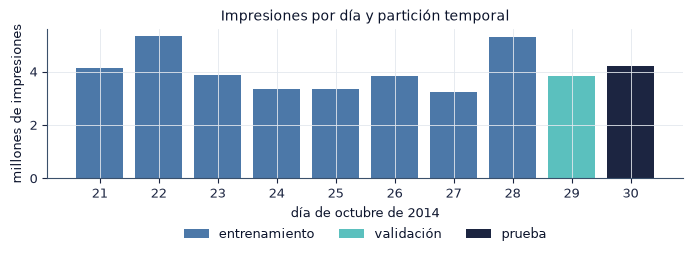

In [4]:
filas = pd.DataFrame({"día": list(fpd), "filas": list(fpd.values())})
filas["partición"] = np.where(filas["día"] <= C.TRAIN_DAYS[-1], "entrenamiento",
                              np.where(filas["día"] == C.VAL_DAY, "validación", "prueba"))
display(filas.set_index("día").T)

fig, ax = plt.subplots(figsize=(7, 2.8))
col = {"entrenamiento": C.BAR, "validación": "#5BC0BE", "prueba": "#1C2541"}
ax.bar(filas["día"], filas["filas"] / 1e6, color=[col[p] for p in filas["partición"]])
ax.set_xlabel("día de octubre de 2014"); ax.set_ylabel("millones de impresiones")
ax.set_title("Impresiones por día y partición temporal"); from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=cc, label=p) for p, cc in col.items()], ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax.set_xticks(filas["día"])
fig.tight_layout(); P.save(fig, "1_6_filas_por_dia"); plt.show()

El conjunto de prueba es el último día observado y no se usa para ninguna decisión de modelado. El día 29 cumple la función de validación: en él elegimos hiperparámetros, el umbral de decisión y la mejor codificación.